# SEMS versus its deterministic forecast-based counterpart

Compare the optimal **root variables** at 12:00, 12:15, 12:30 and 12:45 on
**31 December 2025**. Each optimization looks ahead four 15-minute intervals.
The deterministic model uses scentree's actual point forecast:

```python
forecast = fans["predicted_values"][0]
```

This is the estimator's forecast returned by the same call that generates the
scenario fan. We do not substitute the sampled fan mean or the tree mean.

**Main comparison:** the stochastic and deterministic problems start with the
same SOC at each solve, taken from the previously studied SEMS rolling run.
This isolates the effect of replacing the scenario tree by one forecast path.

**Additional operational comparison:** run a deterministic rolling controller
with its own SOC carried forward. Both controllers start at 50% and execute
only their root actions. Actual PV is used afterwards for settlement.

All model equations, prices, limits and penalty assumptions are shared. Install `requirements.txt`, then
run this notebook from the extracted project directory.



In [10]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyomo.environ as pyo
import scentree
import tomllib

sys.path.insert(0, str(Path("scentree/scentree-main").resolve()))

from scentree.io.loader import Dataset, DatasetsLoader
from scentree.fan_generator import StageManager
from scentree.estimators.estimator_orchestrator import EstimatorController
from scentree.estimators.var import VarEstimator
from scentree.tree_construction.ftc import FTC

PURPLE, BLACK, TEAL = "#7030A0", "#000000", "#5F7C7E"

## 1. Use the same data and four windows

The two CSV extracts come from `lab2_2025.xlsx`: 90 completed historical days
(2 October–30 December) and seven target intervals (12:00–13:30). At solve `j`,
select four shifted historical PV columns and the next four demand/price rows.
Today's PV is excluded from all forecasts. Forecasts retain the original
convention and do not condition on earlier PV observations that day.

PV, demand and energy flows are **kWh per interval**. Spot prices and the
imbalance penalty are **€/kWh**. Timestamps retain the source's fixed CET labels.

In [11]:
history = pd.read_csv("data/pv_history_7_periods.csv", parse_dates=["date"],
                      float_precision="round_trip")
target = pd.read_csv("data/target_7_intervals.csv", parse_dates=["datetime"],
                     float_precision="round_trip")
reference = pd.read_csv("data/reference_sems_root_actions.csv", parse_dates=["start"],
                        float_precision="round_trip")
assert history.shape == (90, 8) and len(target) == 7
assert history.date.max() < target.datetime.min().normalize()
results_dir, figures_dir = Path("results"), Path("figures")
results_dir.mkdir(exist_ok=True)
figures_dir.mkdir(exist_ok=True)
display(target[["datetime", "D", "spot"]])

,datetime,D,spot
0,2025-12-31 12:00:00,0.808694,0.08330
1,2025-12-31 12:15:00,1.306349,0.08200
2,2025-12-31 12:30:00,0.511136,0.08200
3,2025-12-31 12:45:00,1.921605,0.08489
4,2025-12-31 13:00:00,0.803707,0.08310
5,2025-12-31 13:15:00,1.300481,0.08414
6,2025-12-31 13:30:00,1.547746,0.08500


## 2. Generate a new fan and FTC tree for each four-period window

Retain the case study's **VAR-only forecasting method**, 80 fan trajectories,
fan seed **684**, FTC seed **15** and distance exponent **r=30**. These explicit
settings make both notebooks reproducible. FTC determines the branching.

In scentree **0.0.10**, PCA runs only for at least ten input columns by default.
Each shifted window here has four columns, so VAR fits the standardized PV data
directly. The old PCA variance override is removed. The estimator assignment
configures this notebook session without changing the supplied package source.
This retains the original forecasting method for a comparable teaching case.
Automatic estimator selection can produce a different forecast and topology.

`fans["scenarios"][0]` is the sampled fan. `fans["predicted_values"][0]` is its
point forecast in the original PV units. The deterministic comparison uses
that point forecast directly, rather than the fan mean or reduced-tree mean.

In [12]:
EstimatorController.estimator_classes = [VarEstimator]

def make_inputs(Y):
    loader = DatasetsLoader(datasets=[
        Dataset(name="PV", values=Y, stage_ids=[1, 2, 3, 4], bounds=(0., np.inf))
    ])
    fans = StageManager().generate_scenario_fans(
        X=loader.get_full_values(), num_fans=1, num_scenarios=80,
        build_in_sample_fans=False, value_ranges=loader.get_full_bounds(), seed=684,
    )
    forecast = np.asarray(fans["predicted_values"][0], dtype=float).reshape(4)
    assert np.all(np.isfinite(forecast)) and np.all(forecast >= 0)
    trees = FTC(
        scenarios=fans["scenarios"],
        num_variables_per_stage=loader.get_num_variables_per_stage(),
        stage_ids=loader.get_sorted_stage_ids(),
    ).generate_scenario_trees(
        stage_columns_mapping=loader.create_stage_columns_mapping(),
        initial_stage_id_to_cluster=1, r=30., seed=15,
    )
    return fans["scenarios"][0], forecast, trees["nodal_formulation"][0]

def forecast_path(forecast):
    # One root and four successive PV observations, each with probability one.
    return {
        "parent": {0: None, 1: 0, 2: 1, 3: 2, 4: 3},
        "stage": {n: n for n in range(5)},
        "random_variable_value": {0: None, **{
            t+1: np.array([forecast[t]]) for t in range(4)}},
        "probability": {n: 1.0 for n in range(5)},
    }

## 3. Solve the same model on a tree or one forecast path

For each non-root node $n$, with $p=parent[n]$,

$$SOC_n=SOC_p+(charge_p-discharge_p)/60,$$
$$imb^+_n-imb^-_n=PV_n+discharge_p+buy_p-charge_p-sell_p-demand_{s(p)}.$$

The battery is lossless: capacity 60 kWh, SOC bounds 30–80%, and charge/discharge
limits 7.5 kWh per interval. Sales earn spot, purchases cost spot + 0.12, and
absolute imbalance costs 0.30 €/kWh. There is no terminal SOC target, terminal
inventory value or cycling cost. The previously removed grid cap and extra
non-anticipativity ties remain absent.

The deterministic counterpart changes **only** the PV representation: one
forecast path with probabilities one. Reusing the same function keeps every
other equation and bound identical. Each model receives one primary HiGHS solve.

In [13]:
def solve_sems(nodal, demand, price, initial_soc):
    parent = nodal["parent"]
    stage = nodal["stage"]
    xi = nodal["random_variable_value"]
    pi = nodal["probability"]
    root = next(n for n in parent if parent[n] is None)
    model = pyo.ConcreteModel()
    model.charge = pyo.Var([n for n in stage if stage[n] < 4], bounds=(0, 7.5))
    model.discharge = pyo.Var([n for n in stage if stage[n] < 4], bounds=(0, 7.5))
    model.buy = pyo.Var([n for n in stage if stage[n] < 4], domain=pyo.NonNegativeReals)
    model.sell = pyo.Var([n for n in stage if stage[n] < 4], domain=pyo.NonNegativeReals)
    model.soc = pyo.Var(stage, bounds=(0.30, 0.80))
    model.imb_plus = pyo.Var([n for n in parent if parent[n] is not None],
                             domain=pyo.NonNegativeReals)
    model.imb_minus = pyo.Var([n for n in parent if parent[n] is not None],
                              domain=pyo.NonNegativeReals)
    model.soc[root].fix(initial_soc)
    model.constraints = pyo.ConstraintList()
    for n in parent:
        if parent[n] is not None:
            p = parent[n]
            model.constraints.add(model.soc[n] == model.soc[p]
                                  + (model.charge[p] - model.discharge[p]) / 60)
            model.constraints.add(model.imb_plus[n] - model.imb_minus[n]
                                  == xi[n].item() + model.discharge[p] + model.buy[p]
                                  - model.charge[p] - model.sell[p] - demand[stage[p]])
    model.profit = pyo.Objective(sense=pyo.maximize, expr=
        sum(pi[n] * (price[stage[n]] * model.sell[n]
                     - (price[stage[n]] + 0.12) * model.buy[n])
            for n in stage if stage[n] < 4)
        - 0.30 * sum(pi[n] * (model.imb_plus[n] + model.imb_minus[n])
                     for n in parent if parent[n] is not None))
    solution = pyo.SolverFactory("appsi_highs").solve(model)
    pyo.assert_optimal_termination(solution)
    return model, root

## 4. Compare each SEMS problem with its deterministic counterpart

For every window, solve SEMS first. Solve its deterministic counterpart with
the **same initial SOC**. Only the SEMS root action updates the SOC used for the
next paired comparison. The deterministic alternative is evaluated at that
state; these four deterministic alternatives are not one continuous trajectory.

We also solve a separate deterministic rolling controller at its **own** current
SOC. Both controllers use exactly the same forecast at a given clock time.

In [14]:
def root_action(model, root, initial_soc):
    action = {name: pyo.value(getattr(model, name)[root])
              for name in ["charge", "discharge", "buy", "sell"]}
    return {"soc_before": initial_soc, **action,
            "soc_after": initial_soc + (action["charge"] - action["discharge"]) / 60,
            "window_objective_eur": pyo.value(model.profit)}

soc_sems = soc_det = 0.50
runs, paired_rows, rolling_rows, forecasts = [], [], [], []
for j in range(4):
    window = target.iloc[j:j+4].reset_index(drop=True)
    fan, forecast, nodal = make_inputs(history.iloc[:, 1+j:5+j].to_numpy())
    chain = forecast_path(forecast)
    demand, price = window.D.to_numpy(), window.spot.to_numpy()
    start = window.datetime.iloc[0]
    period = f"{start:%H:%M}–{start + pd.Timedelta(minutes=15):%H:%M}"

    sm, sr = solve_sems(nodal, demand, price, soc_sems)
    dm, dr = solve_sems(chain, demand, price, soc_sems)
    rm, rr = solve_sems(chain, demand, price, soc_det)
    sems = root_action(sm, sr, soc_sems)
    det_same = root_action(dm, dr, soc_sems)
    det_rolling = root_action(rm, rr, soc_det)
    for method, action in [("SEMS", sems), ("Deterministic", det_same)]:
        paired_rows.append({"start": start, "period": period, "method": method, **action})
    for method, action in [("SEMS", sems), ("Deterministic", det_rolling)]:
        rolling_rows.append({"start": start, "period": period, "method": method, **action})
    for t in range(4):
        stage, pi, xi = nodal["stage"], nodal["probability"], nodal["random_variable_value"]
        forecasts.append({"solve_start": start, "interval_start": window.datetime.iloc[t],
                          "relative_period": t+1, "PV_forecast": forecast[t],
                          "fan_mean": fan[:, t].mean(),
                          "tree_mean": sum(pi[n] * xi[n].item() for n in stage if stage[n] == t+1)})
    runs.append({"start": start, "window": window, "nodal": nodal, "fan": fan,
                 "forecast": forecast, "chain": chain,
                 "models": [(sm, sr), (dm, dr), (rm, rr)]})
    soc_sems, soc_det = sems["soc_after"], det_rolling["soc_after"]
    print(f"Solved {start:%H:%M}: SEMS, deterministic at same SOC, deterministic rolling")

paired = pd.DataFrame(paired_rows)
rolling = pd.DataFrame(rolling_rows)
forecast_table = pd.DataFrame(forecasts)
display(forecast_table.pivot(index="solve_start", columns="relative_period", values="PV_forecast").round(6))

Building trees: 100%|██████████| 1/1 [00:00<00:00, 39.99it/s]


Solved 12:00: SEMS, deterministic at same SOC, deterministic rolling


Building trees: 100%|██████████| 1/1 [00:00<00:00, 23.54it/s]


Solved 12:15: SEMS, deterministic at same SOC, deterministic rolling


Building trees: 100%|██████████| 1/1 [00:00<00:00, 20.83it/s]


Solved 12:30: SEMS, deterministic at same SOC, deterministic rolling


Building trees: 100%|██████████| 1/1 [00:00<00:00, 112.49it/s]


Solved 12:45: SEMS, deterministic at same SOC, deterministic rolling


relative_period,1,2,3,4
solve_start,,,,
2025-12-31 12:00:00,3.512191,3.504339,3.377664,3.228999
2025-12-31 12:15:00,3.389589,3.127716,2.874753,2.407180
2025-12-31 12:30:00,2.858268,2.856335,2.403475,2.359141
2025-12-31 12:45:00,3.864366,3.258011,3.320153,3.227239


## 5. Root-variable comparison at the same initial SOC

This is the main table. Energy flows are kWh per implemented interval. SOC after
is the state that each root action would produce. Only SEMS supplies the state
for the next paired solve.

Rows show the particular optimal solutions returned by HiGHS. With lossless
storage, no cycling cost and repeated prices, alternative optimal flows may
exist. The net battery and market exchanges help interpret the actions.

,period,method,charge,discharge,buy,sell,SOC before (%),SOC after (%)
0,12:00–12:15,SEMS,0.000000,7.5,0.0,11.008578,50.000000,37.500000
1,12:00–12:15,Deterministic,0.000000,7.5,0.0,10.203497,50.000000,37.500000
2,12:15–12:30,SEMS,2.848675,0.0,0.0,0.000000,37.500000,42.247791
3,12:15–12:30,Deterministic,2.083240,0.0,0.0,0.000000,37.500000,40.972067
4,12:30–12:45,SEMS,3.184803,0.0,0.0,0.000000,42.247791,47.555796
5,12:30–12:45,Deterministic,2.347131,0.0,0.0,0.000000,42.247791,46.159677
6,12:45–13:00,SEMS,0.000000,7.5,0.0,9.316769,47.555796,35.055796
7,12:45–13:00,Deterministic,0.000000,7.5,0.0,9.442761,47.555796,35.055796


,period,charge (Det − SEMS),discharge (Det − SEMS),buy (Det − SEMS),sell (Det − SEMS)
0,12:00–12:15,0.000000,0.0,0.0,-0.805081
1,12:15–12:30,-0.765434,0.0,0.0,0.000000
2,12:30–12:45,-0.837672,0.0,0.0,0.000000
3,12:45–13:00,0.000000,0.0,0.0,0.125991


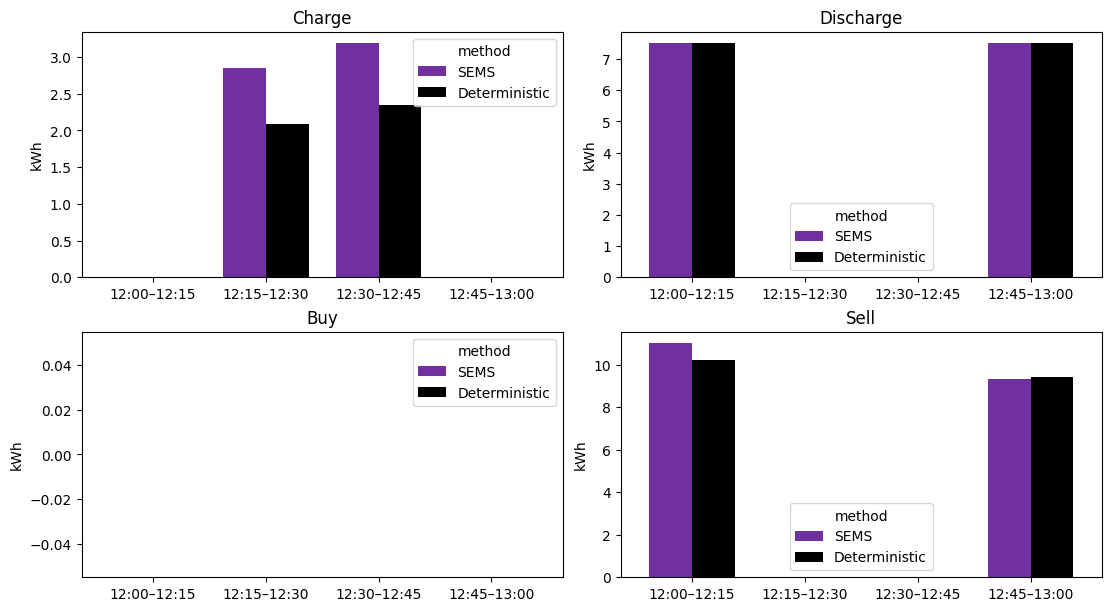

In [15]:
def operation_table(frame):
    table = frame[["period", "method", "charge", "discharge", "buy", "sell"]].copy()
    table["SOC before (%)"] = 100 * frame.soc_before
    table["SOC after (%)"] = 100 * frame.soc_after
    return table.round(6)

display(operation_table(paired))
sems_rows = paired[paired.method == "SEMS"].reset_index(drop=True)
det_rows = paired[paired.method == "Deterministic"].reset_index(drop=True)
delta = det_rows[["period"]].copy()
for name in ["charge", "discharge", "buy", "sell"]:
    delta[name + " (Det − SEMS)"] = det_rows[name] - sems_rows[name]
display(delta.round(6))

fig, axes = plt.subplots(2, 2, figsize=(11, 6), layout="constrained")
for ax, name in zip(axes.flat, ["charge", "discharge", "buy", "sell"]):
    values = paired.pivot(index="period", columns="method", values=name)[["SEMS", "Deterministic"]]
    values.plot.bar(ax=ax, color=[PURPLE, BLACK], width=0.76)
    ax.set(title=name.capitalize(), xlabel="", ylabel="kWh")
    ax.tick_params(axis="x", rotation=0)
fig.savefig(figures_dir / "root_actions_same_soc.png", dpi=180)
plt.show()

## 6. Two independent rolling controllers

This second table is an operational comparison: SEMS and the deterministic
controller each apply their root actions and carry their **own** SOC forward.
The SOC before each solve may now differ. The forecasts remain identical
between controllers because the historical-window convention is unchanged.

,period,method,charge,discharge,buy,sell,SOC before (%),SOC after (%)
0,12:00–12:15,SEMS,0.000000,7.500000,0.0,11.008578,50.000000,37.500000
1,12:00–12:15,Deterministic,0.000000,7.500000,0.0,10.203497,50.000000,37.500000
2,12:15–12:30,SEMS,2.848675,0.000000,0.0,0.000000,37.500000,42.247791
3,12:15–12:30,Deterministic,2.083240,0.000000,0.0,0.000000,37.500000,40.972067
4,12:30–12:45,SEMS,3.184803,0.000000,0.0,0.000000,42.247791,47.555796
5,12:30–12:45,Deterministic,2.347131,0.000000,0.0,0.000000,40.972067,44.883953
6,12:45–13:00,SEMS,0.000000,7.500000,0.0,9.316769,47.555796,35.055796
7,12:45–13:00,Deterministic,0.000000,5.904348,0.0,7.847109,44.883953,35.043373


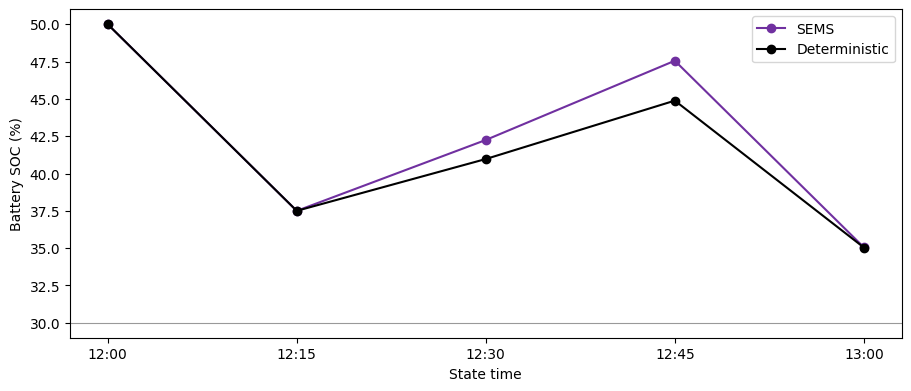

In [16]:
display(operation_table(rolling))
fig, ax = plt.subplots(figsize=(9, 3.8), layout="constrained")
for method, color in [("SEMS", PURPLE), ("Deterministic", BLACK)]:
    rows = rolling[rolling.method == method]
    ax.plot(range(5), np.r_[0.50, rows.soc_after] * 100, "o-", label=method, color=color)
ax.axhline(30, color="0.6", linewidth=0.8)
ax.set(xticks=range(5), xticklabels=["12:00", "12:15", "12:30", "12:45", "13:00"],
       ylabel="Battery SOC (%)", xlabel="State time")
ax.legend()
fig.savefig(figures_dir / "rolling_soc_comparison.png", dpi=180)
plt.show()

## 7. Settle the implemented actions using observed PV

For each independent controller, evaluate the same realized PV and demand:

$$imbalance=PV_{actual}+discharge+buy-charge-sell-demand,$$
$$profit=spot\,sell-(spot+0.12)\,buy-0.30|imbalance|.$$

Sum only the four applied intervals. The optimization objectives cover
overlapping future hours and must not be added. Different terminal SOC values
mean different remaining battery inventories. No salvage value is assigned.
This single observed hour is an illustration, not an out-of-sample claim that
one method generally outperforms the other.

,start,method,PV_actual,demand,signed_imbalance,cash_eur,penalty_eur,profit_eur
0,2025-12-31 12:00:00,SEMS,4.570923,0.808694,0.253651,0.917015,0.076095,0.840919
1,2025-12-31 12:00:00,Deterministic,4.570923,0.808694,1.058732,0.849951,0.317620,0.532332
2,2025-12-31 12:15:00,SEMS,4.577273,1.306349,0.422249,0.000000,0.126675,-0.126675
3,2025-12-31 12:15:00,Deterministic,4.577273,1.306349,1.187684,0.000000,0.356305,-0.356305
4,2025-12-31 12:30:00,SEMS,4.616798,0.511136,0.920859,0.000000,0.276258,-0.276258
5,2025-12-31 12:30:00,Deterministic,4.616798,0.511136,1.758531,0.000000,0.527559,-0.527559
6,2025-12-31 12:45:00,SEMS,4.588496,1.921605,0.850122,0.790901,0.255036,0.535864
7,2025-12-31 12:45:00,Deterministic,4.588496,1.921605,0.724130,0.666141,0.217239,0.448902


,cash_eur,penalty_eur,profit_eur,final_soc_pct
method,,,,
SEMS,1.707915,0.734064,0.973851,35.055796
Deterministic,1.516092,1.418723,0.097369,35.043373


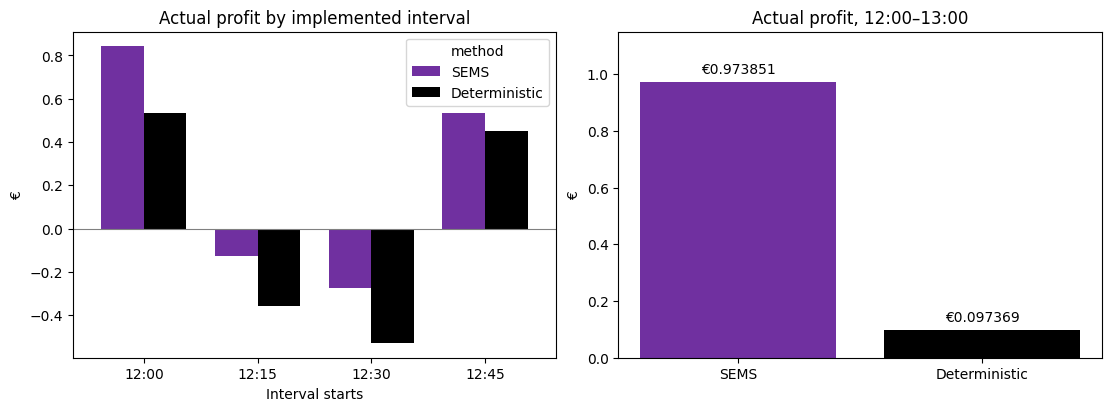

In [17]:
settlements = []
for row in rolling.to_dict("records"):
    actual = target.loc[target.datetime == row["start"]].iloc[0]
    imbalance = (actual.PV + row["discharge"] + row["buy"]
                 - row["charge"] - row["sell"] - actual.D)
    cash = actual.spot * row["sell"] - (actual.spot + 0.12) * row["buy"]
    settlements.append({"start": row["start"], "method": row["method"],
                        "PV_actual": actual.PV, "demand": actual.D,
                        "signed_imbalance": imbalance, "cash_eur": cash,
                        "penalty_eur": 0.30 * abs(imbalance),
                        "profit_eur": cash - 0.30 * abs(imbalance)})
realized = pd.DataFrame(settlements)
totals = realized.groupby("method", sort=False)[["cash_eur", "penalty_eur", "profit_eur"]].sum()
totals["final_soc_pct"] = rolling.groupby("method", sort=False).soc_after.last() * 100
display(realized.round(6))
display(totals.round(6))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
interval_profit = realized.assign(period=realized.start.dt.strftime("%H:%M")).pivot(
    index="period", columns="method", values="profit_eur")[["SEMS", "Deterministic"]]
interval_profit.plot.bar(ax=axes[0], color=[PURPLE, BLACK], width=0.75)
axes[0].axhline(0, color="0.5", linewidth=0.8)
axes[0].set(title="Actual profit by implemented interval", xlabel="Interval starts", ylabel="€")
axes[0].tick_params(axis="x", rotation=0)
total_profit = totals.loc[["SEMS", "Deterministic"], "profit_eur"]
bars = axes[1].bar(total_profit.index, total_profit, color=[PURPLE, BLACK])
axes[1].bar_label(bars, labels=[f"€{v:.6f}" for v in total_profit], padding=4)
axes[1].set(title="Actual profit, 12:00–13:00", ylabel="€", ylim=(0, 1.15))
fig.savefig(figures_dir / "actual_profit_comparison.png", dpi=180)
plt.show()

## 8. Validate the comparison and save reproducible results

Check that the regenerated SEMS roots and objectives reproduce the previous
rolling notebook, that each paired problem uses the same SOC and that every
model satisfies its constraints and bounds. Verify probability mass by stage.
Save the forecasts, paired table, rolling table and realized outcomes.

In [18]:
flows = ["charge", "discharge", "buy", "sell", "soc_before", "soc_after"]
assert np.allclose(sems_rows[flows], reference[flows], atol=1e-9, rtol=0)
assert np.allclose(sems_rows.window_objective_eur, reference.expected_window_profit_eur,
                   atol=1e-9, rtol=0)
assert np.allclose(sems_rows.soc_before, det_rows.soc_before)
violations = []
for run in runs:
    stage, pi = run["nodal"]["stage"], run["nodal"]["probability"]
    assert all(np.isclose(sum(pi[n] for n in stage if stage[n] == s), 1) for s in range(5))
    assert np.allclose([run["chain"]["random_variable_value"][t+1].item() for t in range(4)],
                       run["forecast"])
    for model, root_node in run["models"]:
        assert model.nconstraints() == 2 * (len(model.soc) - 1)
        for c in model.component_data_objects(pyo.Constraint, active=True):
            value = pyo.value(c.body)
            if c.has_lb(): violations.append(max(0., pyo.value(c.lower) - value))
            if c.has_ub(): violations.append(max(0., value - pyo.value(c.upper)))
        for v in model.component_data_objects(pyo.Var):
            if v.has_lb(): violations.append(max(0., pyo.value(v.lb) - v.value))
            if v.has_ub(): violations.append(max(0., v.value - pyo.value(v.ub)))
for method in ["SEMS", "Deterministic"]:
    rows = rolling[rolling.method == method]
    assert np.allclose(rows.soc_before.to_numpy()[1:], rows.soc_after.to_numpy()[:-1])
assert max(violations, default=0.) < 1e-8
for name, frame in [("root_comparison_same_soc", paired), ("independent_rolling_actions", rolling),
                    ("scentree_forecasts", forecast_table), ("realized_settlement", realized)]:
    frame.to_csv(results_dir / (name + ".csv"), index=False, float_format="%.17g")
totals.to_csv(results_dir / "realized_totals.csv", float_format="%.17g")
summary = {
    "forecast_source": 'StageManager output: fans["predicted_values"][0]',
    "primary_comparison": "Same initial SOC in each SEMS/deterministic pair",
    "models_solved": 12, "max_residual": max(violations, default=0.),
    "sems_reference_max_difference": float(np.max(np.abs(sems_rows[flows].to_numpy() - reference[flows].to_numpy()))),
    "paired": json.loads(paired.to_json(orient="records", date_format="iso", double_precision=15)),
    "rolling": json.loads(rolling.to_json(orient="records", date_format="iso", double_precision=15)),
    "forecasts": json.loads(forecast_table.to_json(orient="records", date_format="iso", double_precision=15)),
    "totals": json.loads(totals.reset_index().to_json(orient="records", double_precision=15)),
    "tree_topologies": [[sum(s == k for s in run["nodal"]["stage"].values()) for k in range(5)] for run in runs],
}
(results_dir / "summary.json").write_text(json.dumps(summary, indent=2))
print(f"12 optimal models. Largest feasibility residual: {max(violations):.2e}")
print("SEMS roots and objectives reproduce the previous rolling-horizon notebook.")

12 optimal models. Largest feasibility residual: 1.11e-15
SEMS roots and objectives reproduce the previous rolling-horizon notebook.
